# Perform single-cell quality control

In this notebook, we perform single-cell quality control using coSMicQC. We filter the single cells by identifying outliers with z-scores, and use either combinations of features or one feature for each condition. 

In [1]:
import json
import os
import pathlib

import matplotlib

matplotlib.use("Agg")  # Ensures no GUI windows are opened
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from cosmicqc import find_outliers, label_outliers
from cytodataframe import CytoDataFrame

## Set paths and variables

In [2]:
# Set parameters for papermill to use for processing
# When running as a script, set the plate with the PLATE_ID environment variable
plate_id = os.environ.get("PLATE_ID", "CARD-CelIns-CX7_261031160001")


In [3]:
# Directory with data
data_dir = pathlib.Path("./data/converted_profiles/").resolve(strict=True)

# Directory to save qc labeled data
qc_labeled_dir = pathlib.Path("./data/qc_labeled_profiles/")
qc_labeled_dir.mkdir(parents=True, exist_ok=True)

# Directory to save qc figures
qc_fig_dir = pathlib.Path("./qc_figures/")
qc_fig_dir.mkdir(parents=True, exist_ok=True)

# Load only the thresholds for the plate_id in the sc_qc_thresholds.json file
qc_thresholds_path = pathlib.Path("./sc_qc_thresholds.json").resolve(strict=True)
with open(qc_thresholds_path) as f:
    qc_thresholds = json.load(f)
qc_thresholds = qc_thresholds.get(plate_id, {})
print(
    f"Loaded QC thresholds for {len(qc_thresholds)} conditions from {qc_thresholds_path}"
)

# Metadata columns to include in output data frame (based on compartment)
nuclei_metadata_columns = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Metadata_Nuclei_Location_Center_X",
    "Metadata_Nuclei_Location_Center_Y",
    "Metadata_Image_PathName_OrigDNA",
    "Metadata_Image_FileName_OrigDNA",
    "Metadata_Image_PathName_OrigActin",
    "Metadata_Image_FileName_OrigActin",
    "Nuclei_AreaShape_BoundingBoxMaximum_X",
    "Nuclei_AreaShape_BoundingBoxMaximum_Y",
    "Nuclei_AreaShape_BoundingBoxMinimum_X",
    "Nuclei_AreaShape_BoundingBoxMinimum_Y",
]
cells_metadata_columns = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Metadata_Cells_Location_Center_X",
    "Metadata_Cells_Location_Center_Y",
    "Metadata_Image_PathName_OrigDNA",
    "Metadata_Image_FileName_OrigDNA",
    "Metadata_Image_PathName_OrigActin",
    "Metadata_Image_FileName_OrigActin",
    "Cells_AreaShape_BoundingBoxMaximum_X",
    "Cells_AreaShape_BoundingBoxMaximum_Y",
    "Cells_AreaShape_BoundingBoxMinimum_X",
    "Cells_AreaShape_BoundingBoxMinimum_Y",
]


Loaded QC thresholds for 5 conditions from /home/jenna/targeted_fibrosis_drug_screen/5.validation_plate_profiling/2.preprocessing_features/sc_qc_thresholds.json


## Load in plate to perform QC on

In [4]:
# Set plate path
plate_path = pathlib.Path(f"{data_dir}/{plate_id}_converted.parquet").resolve(
    strict=True
)

# Load the converted plate data
plate_df = pd.read_parquet(plate_path)

# Print the shape of the DataFrame for each plate
print(f"Loaded plate: {plate_path.stem}, Shape: {plate_df.shape}")


Loaded plate: CARD-CelIns-CX7_261031160001_converted, Shape: (14685, 2486)


## Confirm image paths

In [5]:
# Confirm image paths already point to valid local files (no remapping needed for this plate)
example_path = pathlib.Path(
    plate_df["Metadata_Image_PathName_OrigDNA"].dropna().iloc[0]
) / plate_df["Metadata_Image_FileName_OrigDNA"].dropna().iloc[0]
if not example_path.is_file():
    raise FileNotFoundError(f"Example image path does not exist: {example_path}")

# Print example image path
print(plate_df["Metadata_Image_PathName_OrigDNA"].dropna().iloc[0])


/home/jenna/mnt/Way_McKinsey_Cardiac_Fibrosis/Compound_Screen_data/hit_validation_2_cell_painting/Plate 2/CARD-CelIns-CX7_261031160001


In [6]:
# Print example image file
print(plate_df["Metadata_Image_FileName_OrigDNA"].dropna().iloc[0])


CARD-CelIns-CX7_261031160001_B02f09d4.TIF


## Set mapping for outlines

In [7]:
# Define available compartments
compartments = ["Nuclei", "Cells"]

# Create a dictionary of mappings for each compartment.
# The outline TIFFs (e.g. "NucleiOutlines_PLATE_WELL_SITE.tiff") use the raw,
# unpadded site number. The original images (e.g. "PLATE_WELLf09d4.TIF") use an
# "f"-prefixed, zero-padded site token, a channel digit, and an uppercase ".TIF"
# extension, so the original-image regex has to be built to match that format
# (case-insensitively) rather than reusing the outline's site formatting.
mapping_dict = {
    comp: {
        rf"{comp}Outlines_{record['Image_Metadata_Plate']}_{record['Image_Metadata_Well']}_{record['Image_Metadata_Site']}.tiff": (
            rf"(?i){record['Image_Metadata_Plate']}_{record['Image_Metadata_Well']}"
            rf"f{int(record['Image_Metadata_Site']):02d}d\d\.tif"
        )
        for record in plate_df[
            ["Image_Metadata_Plate", "Image_Metadata_Well", "Image_Metadata_Site"]
        ].to_dict(orient="records")
    }
    for comp in compartments
}


## Detect over-segmented nuclei using shape and intensity

In [8]:
# Set mapping for Nuclei compartment
outline_to_orig_mapping = mapping_dict["Nuclei"]


Number of outliers: 201 (1.37%)
Outliers Range:
Nuclei_AreaShape_Solidity Min: 0.5201221941824944
Nuclei_AreaShape_Solidity Max: 0.9684317718940937
Nuclei_Intensity_MassDisplacement_DNA Min: 0.8985700194243571
Nuclei_Intensity_MassDisplacement_DNA Max: 5.959046197021356


,Metadata_Image_FileName_OrigDNA,Nuclei_AreaShape_Solidity,Nuclei_Intensity_MassDisplacement_DNA
2867,,0.866190,5.959046
10978,,0.920648,5.947830
5197,,0.960090,5.705694
609,,0.520122,5.683366
2981,,0.926267,5.177500

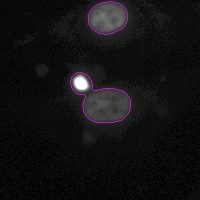
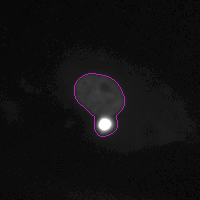
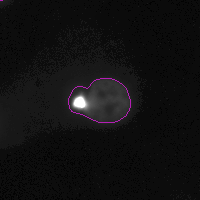
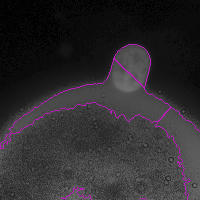
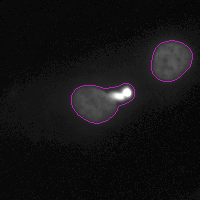

In [9]:
# Find large nuclei outliers for the current plate
oversegmented_nuclei_outliers = find_outliers(
    df=plate_df,
    metadata_columns=nuclei_metadata_columns,
    feature_thresholds=qc_thresholds.get("oversegmented_nuclei", {}),
)

# Convert to CytoDataFrame for outline viewing
oversegmented_nuclei_outliers_cdf = CytoDataFrame(
    data=pd.DataFrame(oversegmented_nuclei_outliers),
    data_outline_context_dir=f"../1.cellprofiler_processing/cp_output/{plate_id}/",
    segmentation_file_regex=outline_to_orig_mapping,
    display_options={
        "center_dot": False,
        "brightness": 5,
        "outline_color": (180, 30, 180),
        # crop a larger window around each object's center to see more context
        "offset_bounding_box": {
            "x_min": -100,
            "y_min": -100,
            "x_max": 100,
            "y_max": 100,
        },
    },
)[
    [
        "Metadata_Image_FileName_OrigDNA",
        "Nuclei_AreaShape_Solidity",
        "Nuclei_Intensity_MassDisplacement_DNA",
    ]
]

oversegmented_nuclei_outliers_cdf.sort_values(
    by="Nuclei_Intensity_MassDisplacement_DNA", ascending=False
).head(5)


## Detect high intensity nuclei

Number of outliers: 93 (0.63%)
Outliers Range:
Nuclei_Intensity_MeanIntensity_DNA Min: 0.08853778244737288
Nuclei_Intensity_MeanIntensity_DNA Max: 0.2244877682719313


,Nuclei_Intensity_MeanIntensity_DNA,Metadata_Image_FileName_OrigDNA
4117,0.088538,
1971,0.088619,
457,0.088715,
844,0.088878,
11551,0.088984,

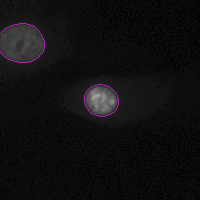
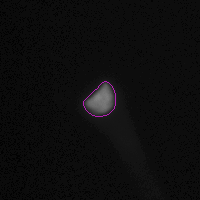
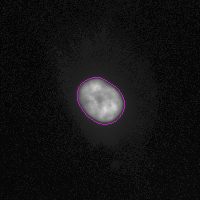
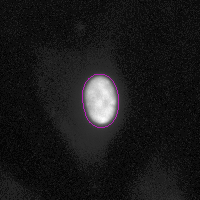
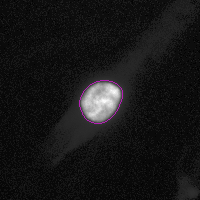

In [10]:
# Find high intensity nuclei outliers for the current plate
high_intensity_outliers = find_outliers(
    df=plate_df,
    metadata_columns=nuclei_metadata_columns,
    feature_thresholds=qc_thresholds.get("high_intensity_nuclei", {}),
)

# Convert to CytoDataFrame for outline viewing
high_intensity_outliers_cdf = CytoDataFrame(
    data=pd.DataFrame(high_intensity_outliers),
    data_outline_context_dir=f"../1.cellprofiler_processing/cp_output/{plate_id}/",
    segmentation_file_regex=outline_to_orig_mapping,
    display_options={
        "center_dot": False,
        "brightness": 5,
        "outline_color": (180, 30, 180),
        # crop a larger window around each object's center to see more context
        "offset_bounding_box": {
            "x_min": -100,
            "y_min": -100,
            "x_max": 100,
            "y_max": 100,
        },
    },
)[
    [
        "Nuclei_Intensity_MeanIntensity_DNA",
        "Metadata_Image_FileName_OrigDNA",
    ]
]

high_intensity_outliers_cdf.sort_values(
    by="Nuclei_Intensity_MeanIntensity_DNA", ascending=True
).head(5)


## Detect under-segmented cells

### Set up outlines for cells

In [11]:
# Set mapping for Cells compartment
outline_to_orig_mapping = mapping_dict["Cells"]


Number of outliers: 118 (0.80%)
Outliers Range:
Cells_AreaShape_Area Min: 1078.0
Cells_AreaShape_Area Max: 7769.0


,Cells_AreaShape_Area,Metadata_Image_FileName_OrigActin
6521,7769.0,
5551,7757.0,
14043,7751.0,
12904,7681.0,
14423,7588.0,
5109,7581.0,
3846,7544.0,
4704,7542.0,
11072,7542.0,
7538,7511.0,

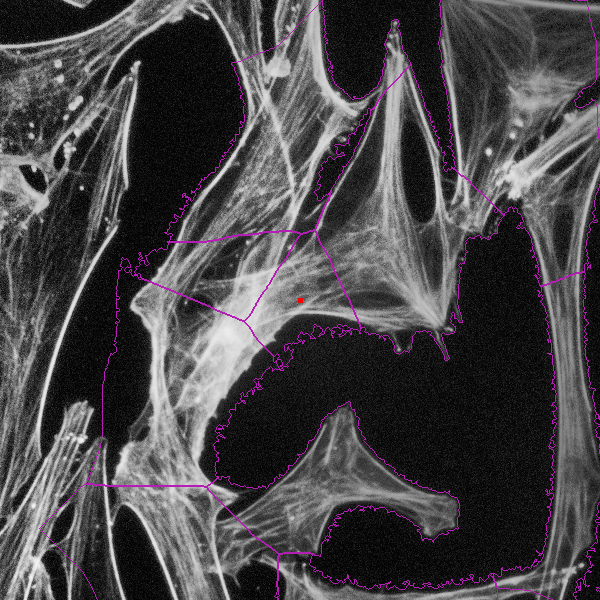
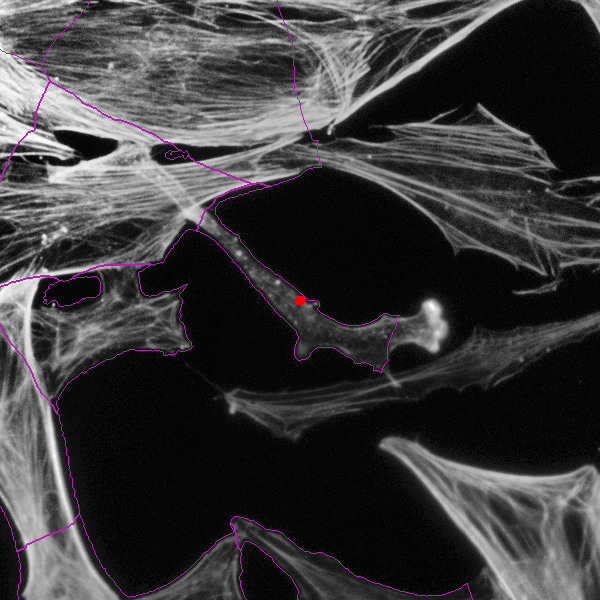
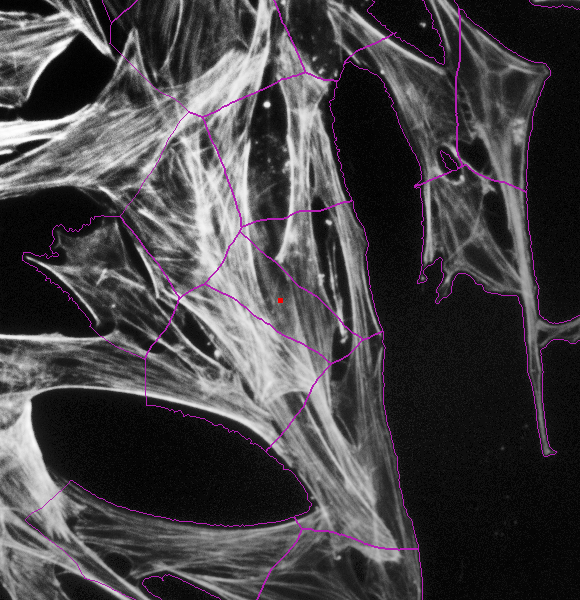
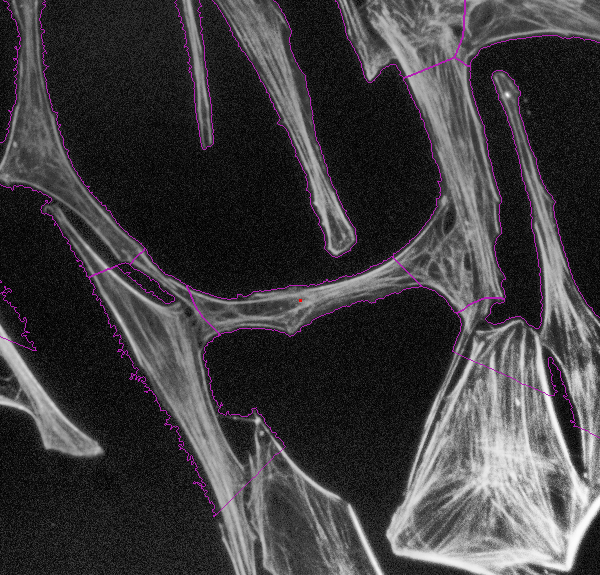
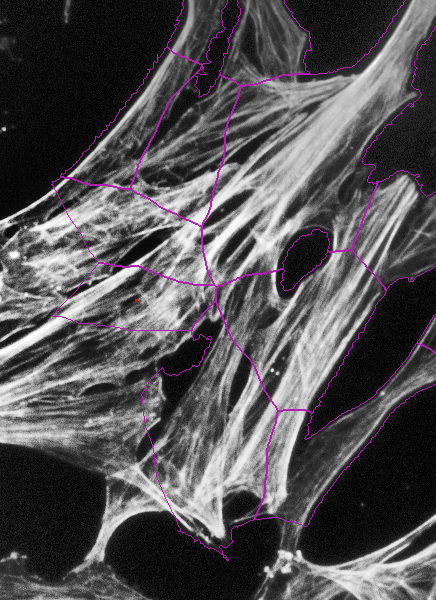
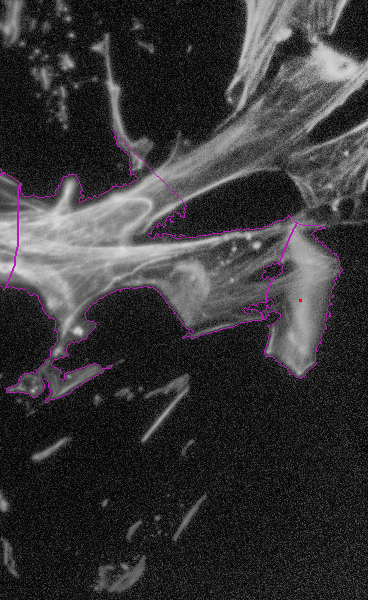
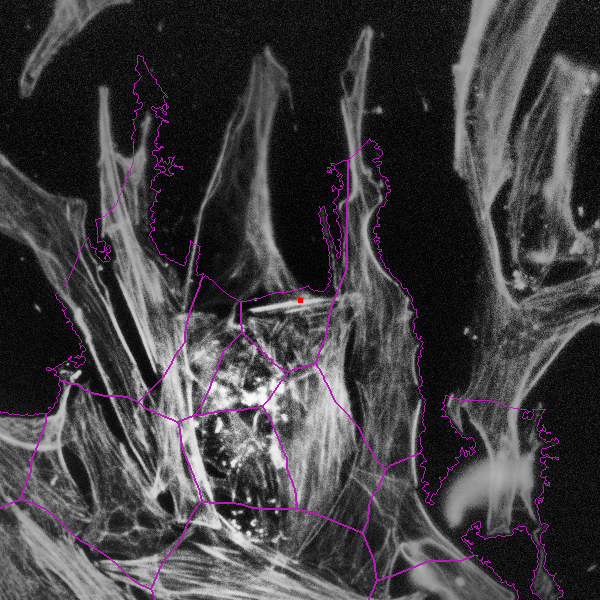
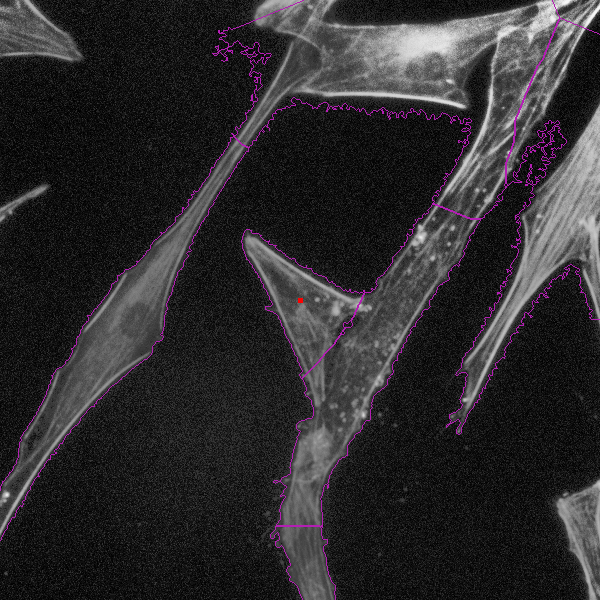
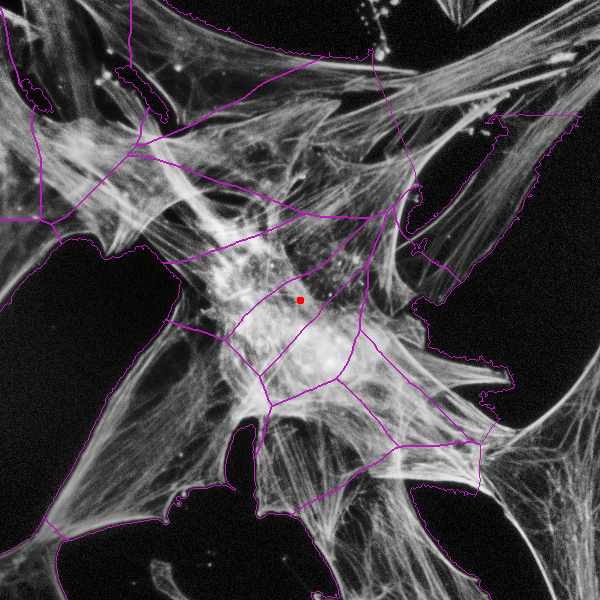
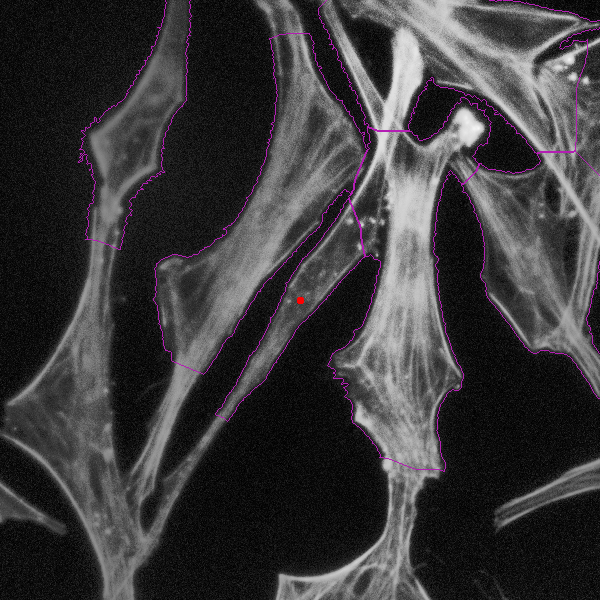

In [12]:
# Find under-segmented cells outliers for the current plate
small_cells_outliers = find_outliers(
    df=plate_df,
    metadata_columns=cells_metadata_columns,
    feature_thresholds=qc_thresholds.get("undersegmented_cells", {}),
)

# Convert to CytoDataFrame for outline viewing
small_cells_outliers_cdf = CytoDataFrame(
    data=pd.DataFrame(small_cells_outliers),
    data_outline_context_dir=f"../1.cellprofiler_processing/cp_output/{plate_id}/",
    segmentation_file_regex=outline_to_orig_mapping,
    display_options={
        "center_dot": True,
        "brightness": 5,
        "outline_color": (180, 30, 180),
        # crop a larger window around each object's center to see more context
        "offset_bounding_box": {
            "x_min": -300,
            "y_min": -300,
            "x_max": 300,
            "y_max": 300,
        },
    },
)[
    [
        "Cells_AreaShape_Area",
        "Metadata_Image_FileName_OrigActin",
    ]
]

small_cells_outliers_cdf.sort_values(
    by="Cells_AreaShape_Area", ascending=False
).head(10)


## Detect out of focus/blurry cells

Number of outliers: 238 (1.62%)
Outliers Range:
Cells_Granularity_1_Actin Min: 10.536002891558956
Cells_Granularity_1_Actin Max: 26.067881365963512


,Cells_Granularity_1_Actin,Metadata_Image_FileName_OrigActin
6266,26.067881,
12673,26.066414,
7085,26.058233,
9594,26.055244,
12523,26.036518,
3155,26.021172,
4106,26.020300,
8942,26.016616,
2794,25.972942,
3738,25.970968,

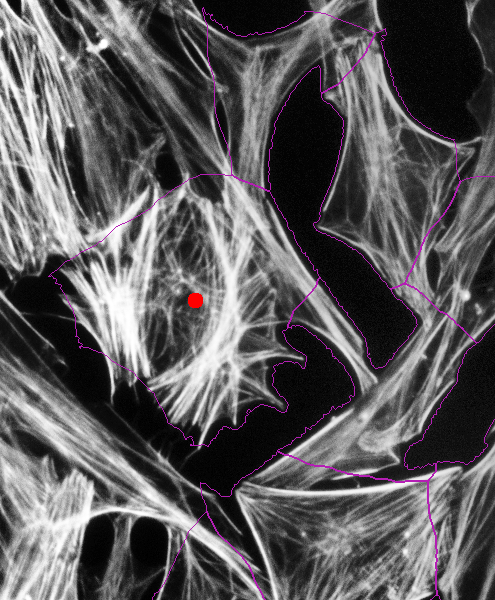
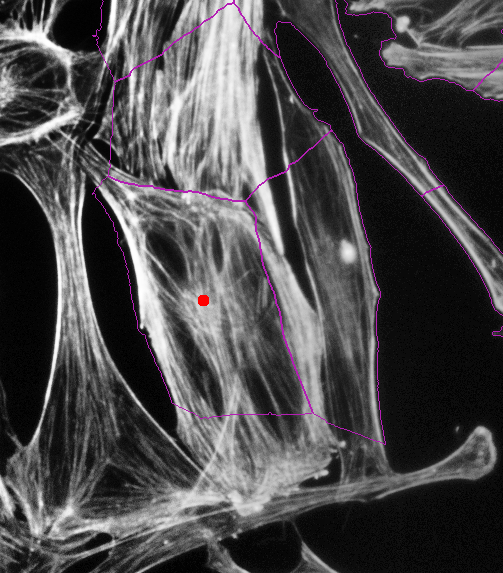
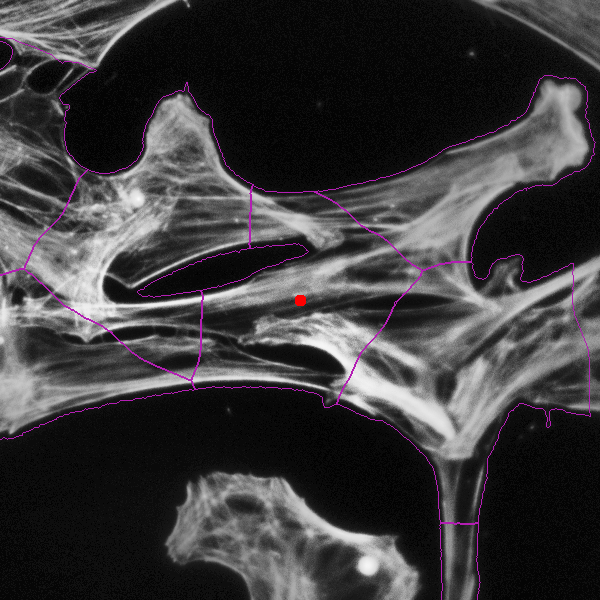
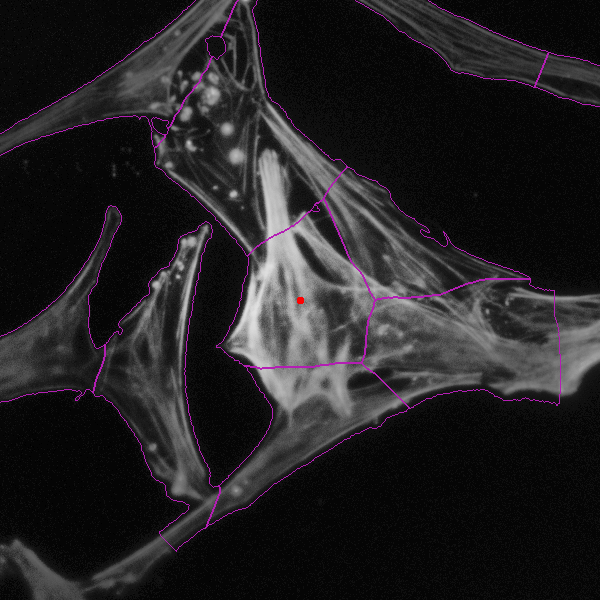
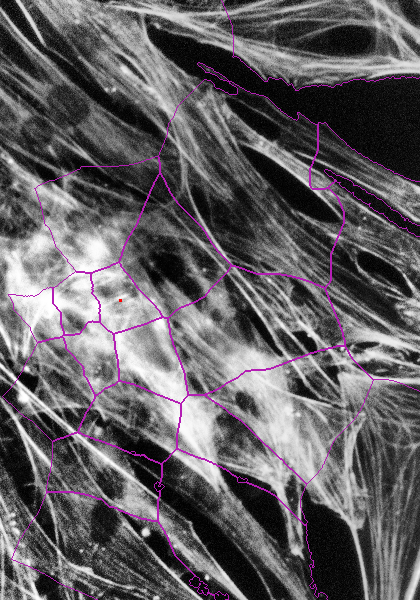
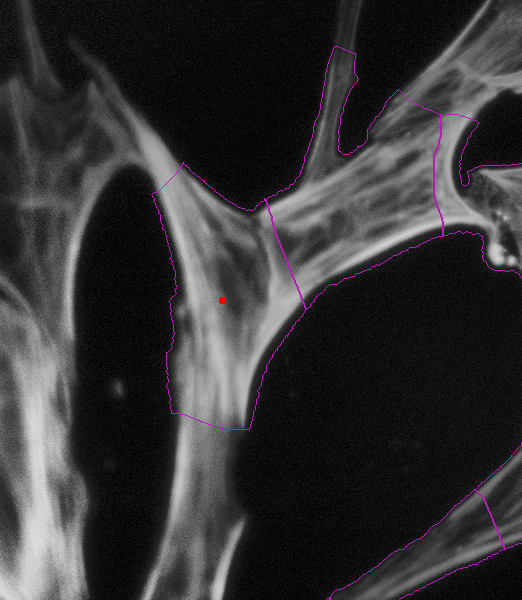
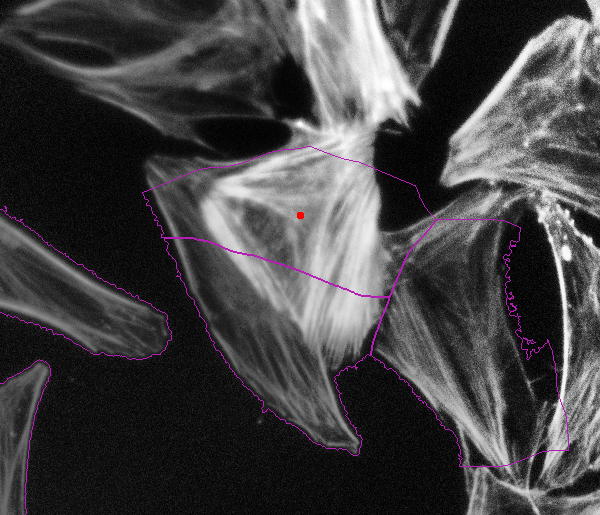
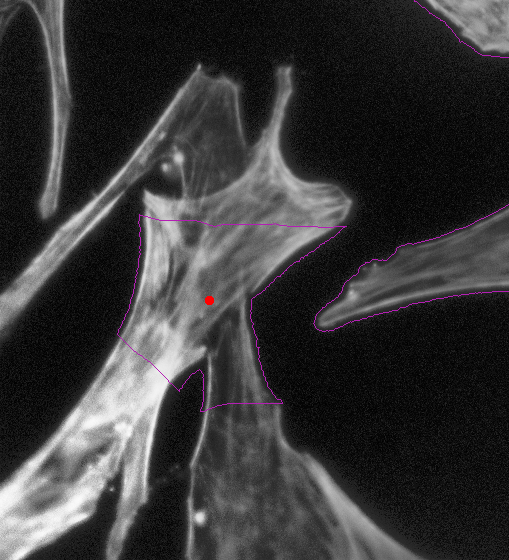
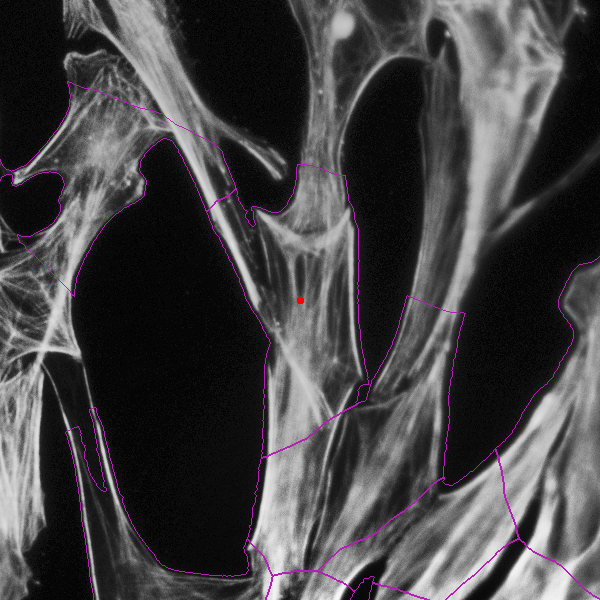
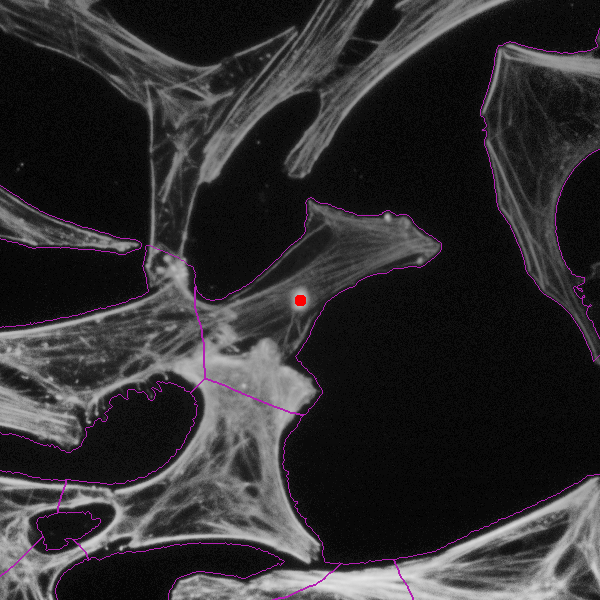

In [13]:
# Find blurry cells outliers for the current plate
blurry_cells_outliers = find_outliers(
    df=plate_df,
    metadata_columns=cells_metadata_columns,
    feature_thresholds=qc_thresholds.get("blurry_cells", {}),
)

# Convert to CytoDataFrame for outline viewing
blurry_cells_outliers_cdf = CytoDataFrame(
    data=pd.DataFrame(blurry_cells_outliers),
    data_outline_context_dir=f"../1.cellprofiler_processing/cp_output/{plate_id}/",
    segmentation_file_regex=outline_to_orig_mapping,
    display_options={
        "center_dot": True,
        "brightness": 5,
        "outline_color": (180, 30, 180),
        # crop a larger window around each object's center to see more context
        "offset_bounding_box": {
            "x_min": -300,
            "y_min": -300,
            "x_max": 300,
            "y_max": 300,
        },
    },
)[
    [
        "Cells_Granularity_1_Actin",
        "Metadata_Image_FileName_OrigActin",
    ]
]

blurry_cells_outliers_cdf.sort_values(
    by="Cells_Granularity_1_Actin", ascending=False
).head(10)


## Detect mis-segmented cells based on number of indentations

We have seen that due to low staining in some Actin FOVs that segmentation will mis-segment to include more background than it should.

Number of outliers: 1585 (10.79%)
Outliers Range:
Cells_Intensity_MeanIntensity_Actin Min: 0.0027425191260575113
Cells_Intensity_MeanIntensity_Actin Max: 0.0051371940411029954
Cells_AreaShape_FormFactor Min: 0.01915695349445557
Cells_AreaShape_FormFactor Max: 0.21310614787762405


,Metadata_Image_FileName_OrigActin,Cells_AreaShape_FormFactor,Cells_Intensity_MeanIntensity_Actin
1196,,0.213106,0.004810
470,,0.212973,0.004330
11042,,0.212924,0.004534
1742,,0.212819,0.003791
4356,,0.212786,0.004553
10350,,0.212583,0.004145
9493,,0.212498,0.004952
432,,0.212428,0.004665
5516,,0.212210,0.005008
12588,,0.212092,0.004170

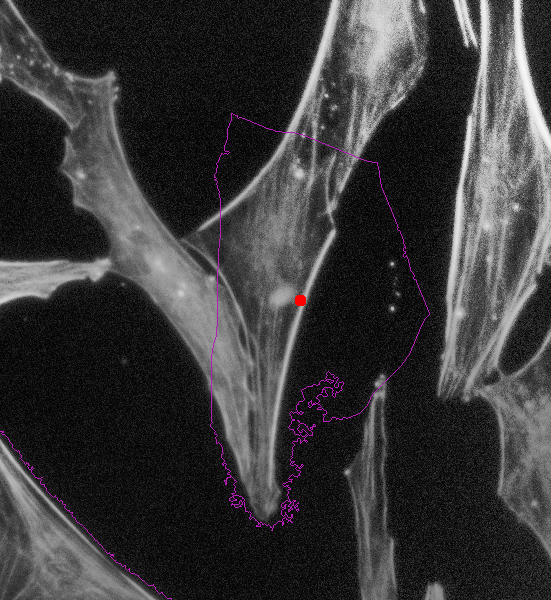
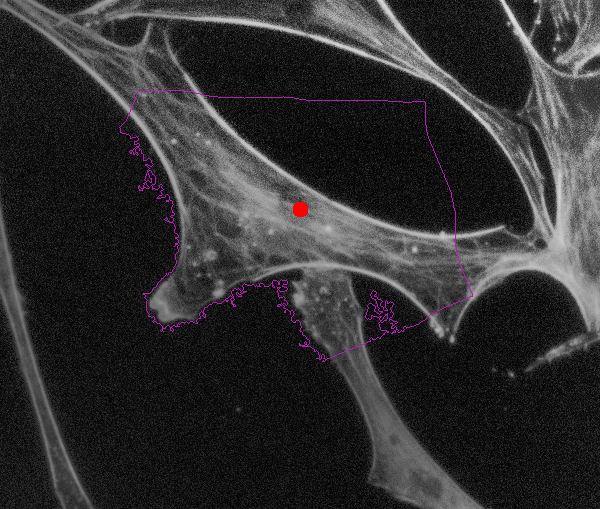
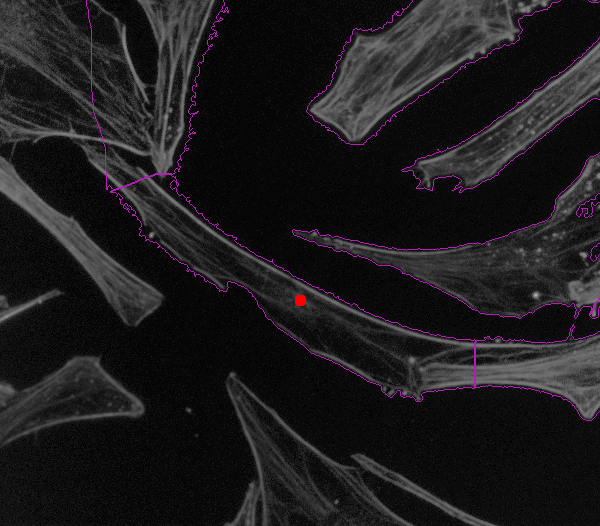
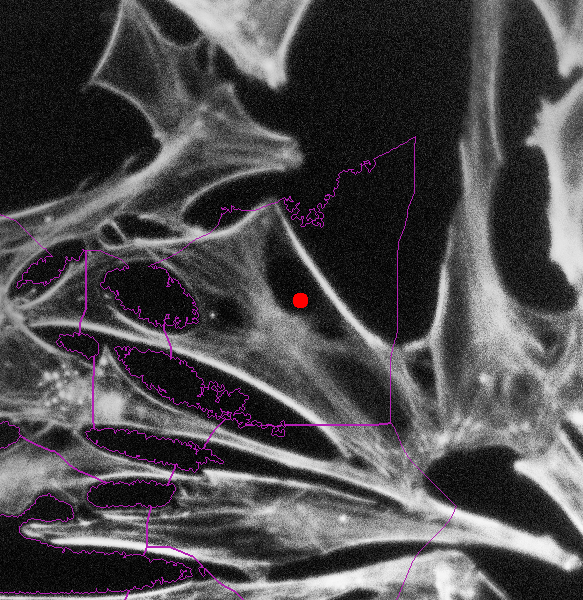
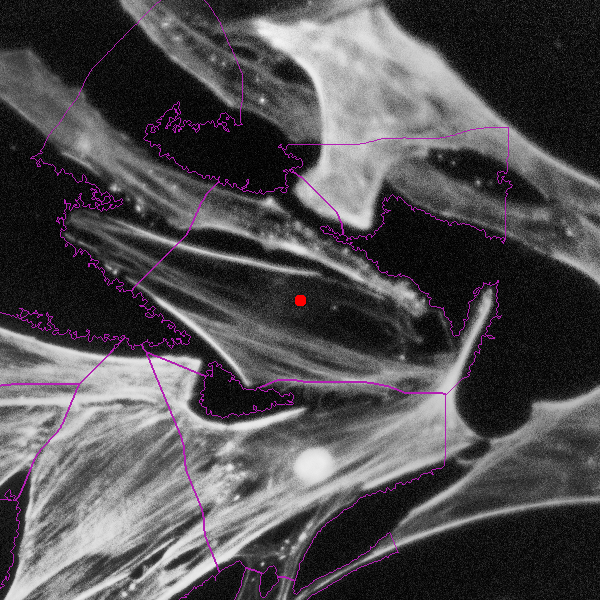
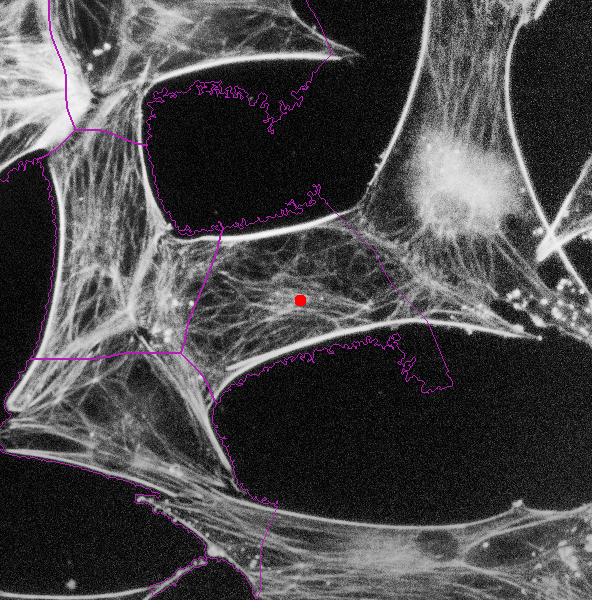
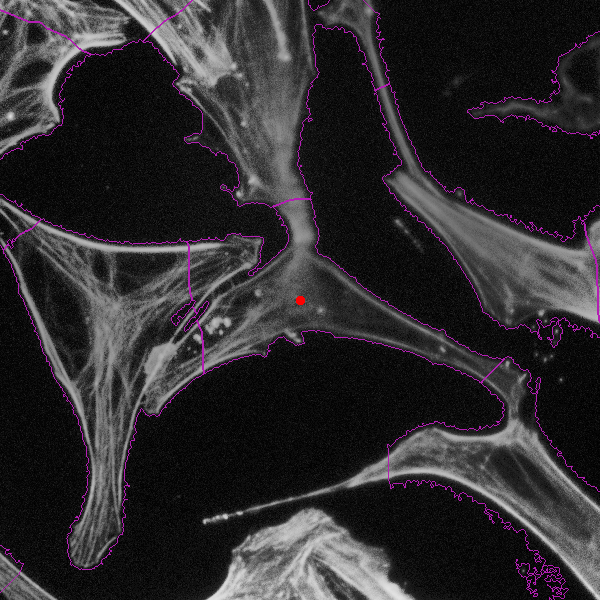
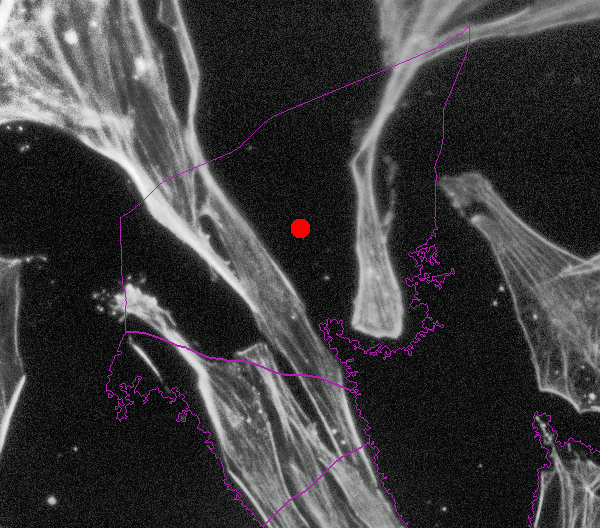
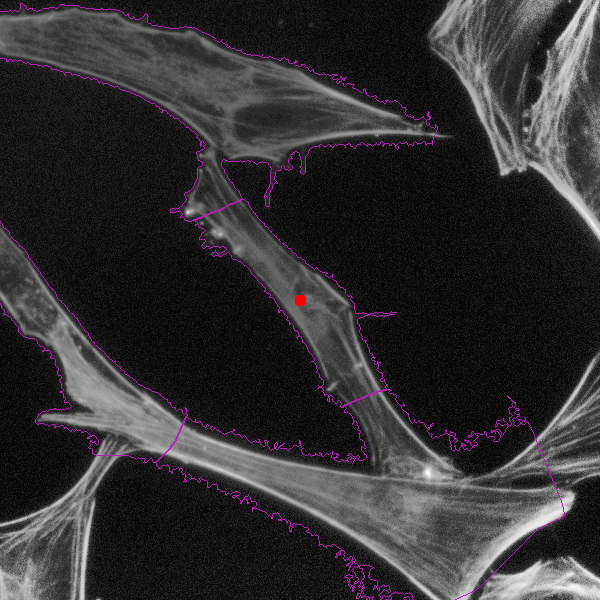
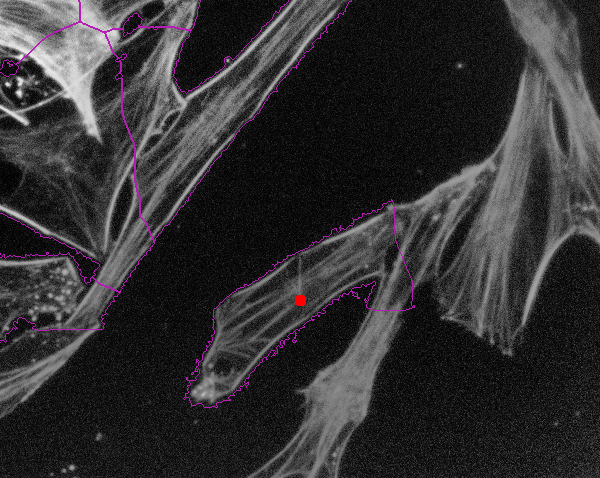

In [14]:
# Find mis-segmented cells outliers for the current plate
missegmented_cells_outliers = find_outliers(
    df=plate_df,
    metadata_columns=cells_metadata_columns,
    feature_thresholds=qc_thresholds.get("missegmented_cells", {}),
)

# Convert to CytoDataFrame for outline viewing
missegmented_cells_outliers_cdf = CytoDataFrame(
    data=pd.DataFrame(missegmented_cells_outliers),
    data_outline_context_dir=f"../1.cellprofiler_processing/cp_output/{plate_id}/",
    segmentation_file_regex=outline_to_orig_mapping,
    display_options={
        "center_dot": True,
        "brightness": 1,
        "outline_color": (180, 30, 180),
        # crop a larger window around each object's center to see more context
        "offset_bounding_box": {
            "x_min": -300,
            "y_min": -300,
            "x_max": 300,
            "y_max": 300,
        },
    },
)[
    [
        "Metadata_Image_FileName_OrigActin",
        "Cells_AreaShape_FormFactor",
        "Cells_Intensity_MeanIntensity_Actin",
    ]
]

missegmented_cells_outliers_cdf.sort_values(
    by="Cells_AreaShape_FormFactor", ascending=False
).head(10)


## Label outliers and save data for the plate

We label every cell with `label_outliers`, using all of the plate's conditions in `sc_qc_thresholds.json` at once.
This adds one `Metadata_cqc_<condition>_is_outlier` column per condition, and the full profiles with these labels are saved as the QC-labeled profiles.
The `find_outliers` results above are only used to look at example outlier cells.

In [15]:
# Label the outliers for every condition and save the full profiles with the labels
qc_labeled_path = qc_labeled_dir / f"{plate_id}_qc_labeled.parquet"
labeled_df = pd.DataFrame(
    label_outliers(
        df=plate_df,
        feature_thresholds=qc_thresholds,
        export_path=str(qc_labeled_path),
    )
)

# Determine cells that failed any QC condition
qc_fail_cols = [col for col in labeled_df.columns if col.startswith("Metadata_cqc_")]
failed_mask = labeled_df[qc_fail_cols].any(axis=1)

# Print the percentage of cells that failed each condition
print((labeled_df[qc_fail_cols].mean() * 100).round(2).to_string())

# Verify the result and include the percentage of failed QC
print(
    f"QC labeled data saved for plate {plate_id}. "
    f"Shape: {labeled_df.shape}. Total percent nuclei failed QC: {failed_mask.mean() * 100:.2f}%"
)

QC labeled data saved for plate CARD-CelIns-CX7_261031160001. Shape: (14685, 2491). Total percent nuclei failed QC: 14.57%


In [16]:
oversegmented_mask = labeled_df["Metadata_cqc_oversegmented_nuclei_is_outlier"]
high_intensity_mask = labeled_df["Metadata_cqc_high_intensity_nuclei_is_outlier"]

# Set the default value to 'Single-cell passed QC'
labeled_df["Outlier_Status"] = "Single-cell passed QC"

# Label each outlier type, excluding small cells
labeled_df.loc[oversegmented_mask, "Outlier_Status"] = "Over-segmented nuclei"
labeled_df.loc[high_intensity_mask, "Outlier_Status"] = "High intensity nuclei"

# Create scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=labeled_df,
    x="Nuclei_AreaShape_Solidity",
    y="Nuclei_Intensity_MassDisplacement_DNA",
    hue="Outlier_Status",
    palette={
        "Single-cell passed QC": "#006400",
        "Over-segmented nuclei": "#990090",
        "High intensity nuclei": "#D55E00",
    },
    alpha=0.6,
)

# Add threshold lines
plt.axvline(
    x=labeled_df.loc[oversegmented_mask, "Nuclei_AreaShape_Solidity"].max(),
    color="r",
    linestyle="--",
    label="Min. threshold for Nuclei Solidity",
)
plt.axhline(
    y=labeled_df.loc[oversegmented_mask, "Nuclei_Intensity_MassDisplacement_DNA"].min(),
    color="b",
    linestyle="--",
    label="Min. threshold for Nuclei Mass Displacement",
)

# Add title and labels
plt.title(f"Nuclei Solidity vs. Mass Displacement ({plate_id})")
plt.xlabel("Nuclei Solidity")
plt.ylabel("Nuclei Mass Displacement (DNA)")
plt.tight_layout()

# Show the legend
plt.legend(loc="upper left", bbox_to_anchor=(0, 1.0), prop={"size": 10})

# Save the figure with plate_id in filename
plt.savefig(qc_fig_dir / f"{plate_id}_nuclei_outliers.png", dpi=500)
plt.close()

In [17]:
small_cells_threshold = labeled_df.loc[
    labeled_df["Metadata_cqc_undersegmented_cells_is_outlier"], "Cells_AreaShape_Area"
].max()

# Create KDE plot of all cells
plt.figure(figsize=(10, 6))
sns.kdeplot(
    x=labeled_df["Cells_AreaShape_Area"],
    fill=True,
    color="#4682B4",  # steel blue
    alpha=0.6,
)

# Add threshold line for small cells
plt.axvline(
    x=small_cells_threshold,
    color="r",
    linestyle="--",
    label=f"Small cells threshold: < {small_cells_threshold:.2f}",
)

# Labels and title
plt.ylabel("Density")
plt.xlabel("Cells Area")
plt.title(f"Distribution of Cell Areas ({plate_id})")
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(qc_fig_dir / f"{plate_id}_small_cell_outliers.png", dpi=500)
plt.close()